In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
data=pd.read_csv('preprocessing.csv')

In [3]:
data.head()

,scholarship_received,placement_status,starting_salary_usd,gpa_or_score,test_score,origin_country_Finland,origin_country_Germany,origin_country_India,origin_country_Ireland,origin_country_Russia,...,visa_status_Schengen Student Visa,visa_status_Student Visa,visa_status_Study Permit,visa_status_Tier 4,post_graduation_visa_OPT,post_graduation_visa_PSW,post_graduation_visa_Post-Study Visa,post_graduation_visa_Work Permit,study_duration,Salary_Bin
0,0,1,0.242883,1.556464,0.679688,1,0,0,0,0,...,0,0,0,1,0,0,0,1,1.0,1
1,1,1,0.219806,-1.488781,0.765584,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0.0,1
2,1,1,0.365432,-0.658260,1.023273,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0.0,2
3,1,0,0.000000,-1.281151,0.336103,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0.0,1
4,1,0,0.000000,-0.589050,-1.210030,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0.5,1


In [4]:
data.shape

(4018, 172)

In [5]:

X = data.drop("placement_status", axis=1)

In [6]:
# Define target
y = data["placement_status"]

# Define features, dropping leaky columns
X = data.drop(["starting_salary_usd", "Salary_Bin"], axis=1)
X = X.drop([col for col in X.columns if col.startswith('placement_')], axis=1)

In [7]:
correlations = pd.concat([X, y], axis=1).corr()['placement_status'].sort_values(ascending=False)
print(correlations.head(30))

placement_status                                            1.000000
field_of_study_Engineering                                  0.045214
destination_city_Vancouver                                  0.035881
destination_city_Birmingham                                 0.035158
destination_country_India                                   0.031925
university_name_Simon Fraser University                     0.027628
university_name_Higher School of Economics                  0.027493
destination_city_Pilani                                     0.026606
language_proficiency_test_IELTS                             0.025285
destination_city_Moscow                                     0.024658
destination_city_Galway                                     0.024257
destination_city_Kingston                                   0.024164
university_name_University of British Columbia              0.023073
destination_city_Mumbai                                     0.023073
destination_city_Manchester       

In [8]:
print(X.columns.tolist())

['scholarship_received', 'gpa_or_score', 'test_score', 'origin_country_Finland', 'origin_country_Germany', 'origin_country_India', 'origin_country_Ireland', 'origin_country_Russia', 'origin_country_South Africa', 'origin_country_United Arab Emirates', 'origin_country_United Kingdom', 'origin_country_United States', 'destination_country_Finland', 'destination_country_Germany', 'destination_country_India', 'destination_country_Ireland', 'destination_country_Russia', 'destination_country_South Africa', 'destination_country_United Arab Emirates', 'destination_country_United Kingdom', 'destination_country_United States', 'destination_city_Abu Dhabi', 'destination_city_Bangalore', 'destination_city_Berlin', 'destination_city_Birmingham', 'destination_city_Boston', 'destination_city_Cambridge', 'destination_city_Cape Town', 'destination_city_Chennai', 'destination_city_Chicago', 'destination_city_Cork', 'destination_city_Delhi', 'destination_city_Dubai', 'destination_city_Dublin', 'destinatio

In [9]:
from sklearn.decomposition import PCA

# Apply PCA to retain 95% of the variance
pca = PCA(n_components=0.95)
data_pca = pca.fit_transform(X)

# Check how many components were kept
print("Original shape:", X.shape)
print("Reduced shape:", data_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:", pca.explained_variance_ratio_.sum())

# Convert PCA result back to DataFrame
X_pca = pd.DataFrame(data_pca, columns=[f"PC{i+1}" for i in range(data_pca.shape[1])])

# Ensure y is a DataFrame (and reset index to match)
y_df = pd.DataFrame(y).reset_index(drop=True)

# Combine PCA results with target
final_df = pd.concat([X_pca, y_df], axis=1)
print(final_df.head())


Original shape: (4018, 147)
Reduced shape: (4018, 84)
Explained variance ratio: [0.1051526  0.10222717 0.02663651 0.02614604 0.02543495 0.02207555
 0.02146788 0.02127155 0.0204753  0.02028944 0.01984608 0.01820197
 0.01795211 0.01777467 0.01741657 0.01719066 0.01673716 0.01617449
 0.01563489 0.01472546 0.01443987 0.01385056 0.01334301 0.01330738
 0.01310186 0.01298656 0.0127805  0.01265761 0.01249175 0.01211105
 0.0105315  0.01042345 0.01020446 0.00983958 0.00968727 0.00951022
 0.00909573 0.00888779 0.00758314 0.00724223 0.00707334 0.00706795
 0.00696204 0.00689698 0.00685116 0.00673198 0.00670566 0.00667172
 0.00662835 0.00639113 0.00632999 0.00622101 0.00579559 0.00445425
 0.00431895 0.00413345 0.00410291 0.00394939 0.0035066  0.00347774
 0.00328067 0.00320138 0.00316807 0.0031545  0.00311636 0.00279828
 0.0026805  0.00207846 0.001964   0.00180411 0.00169256 0.0016851
 0.00167284 0.00165199 0.00163671 0.00162869 0.0016055  0.00156564
 0.00155304 0.00153769 0.00153448 0.00152942 0.001

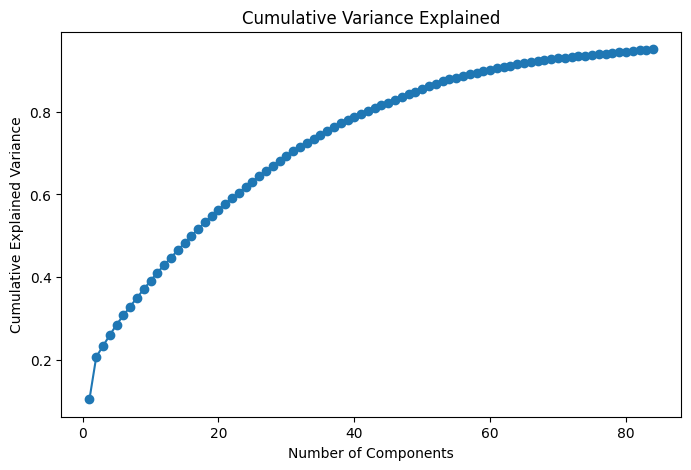

In [10]:
plt.figure(figsize=(8,5))
plt.plot(range(1, len(pca.explained_variance_ratio_)+1),
         pca.explained_variance_ratio_.cumsum(), marker='o')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Variance Explained")
plt.show()

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
# 2. Import model
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

In [13]:
X_model = X.copy()
y_model =y.copy()

In [14]:
X_train, X_test, y_train, y_test = train_test_split( X_model, y_model, test_size=0.2, stratify=y_model, random_state=42)

In [15]:
#  Random Forest
rf= RandomForestClassifier()
rf.fit(X_train, y_train)


RandomForestClassifier()

In [16]:

param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10]
}

grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_rf.fit(X_train, y_train)

print("Best Parameters (Random Forest):", grid_rf.best_params_)
print("Best Cross-Validation Accuracy:", grid_rf.best_score_)

y_pred_rf = grid_rf.best_estimator_.predict(X_test)
print("Test Accuracy:", accuracy_score(y_test, y_pred_rf))


Best Parameters (Random Forest): {'criterion': 'entropy', 'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
Best Cross-Validation Accuracy: 0.5102692305828888
Test Accuracy: 0.5


In [17]:

param_dist_rf = {
    'n_estimators': [100, 150, 200, 250, 300],
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'bootstrap': [True, False]
}

rand_rf = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist_rf,
    n_iter=10,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)
rand_rf.fit(X_train, y_train)

print("Best Parameters (Random Forest):", rand_rf.best_params_)
print("Best CV Accuracy:", rand_rf.best_score_)

y_pred_rf = rand_rf.best_estimator_.predict(X_test)
print("Test Accuracy:", accuracy_score(y_test, y_pred_rf))


Best Parameters (Random Forest): {'n_estimators': 100, 'min_samples_split': 5, 'max_depth': None, 'criterion': 'gini', 'bootstrap': True}
Best CV Accuracy: 0.5055973023647912
Test Accuracy: 0.513681592039801


In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# ---- Random Forest: Compare GridSearchCV vs RandomizedSearchCV ----
print("🔹 Random Forest Evaluation Comparison")
print("=" * 60)

# --- GridSearchCV Best Model ---
best_rf_grid = grid_rf.best_estimator_

y_pred_rf_grid = best_rf_grid.predict(X_test)
y_prob_rf_grid = best_rf_grid.predict_proba(X_test)[:, 1]

print("\nGridSearchCV Results:")
print("Best Parameters:", grid_rf.best_params_)
print("CV Accuracy    :", grid_rf.best_score_)
print("Test Accuracy  :", accuracy_score(y_test, y_pred_rf_grid))
print("Precision      :", precision_score(y_test, y_pred_rf_grid))
print("Recall         :", recall_score(y_test, y_pred_rf_grid))
print("F1 Score       :", f1_score(y_test, y_pred_rf_grid))
print("AUC Score      :", roc_auc_score(y_test, y_prob_rf_grid))

# --- RandomizedSearchCV Best Model ---
best_rf_random = rand_rf.best_estimator_

y_pred_rf_random = best_rf_random.predict(X_test)
y_prob_rf_random = best_rf_random.predict_proba(X_test)[:, 1]

print("\nRandomizedSearchCV Results:")
print("Best Parameters:", rand_rf.best_params_)
print("CV Accuracy    :", rand_rf.best_score_)
print("Test Accuracy  :", accuracy_score(y_test, y_pred_rf_random))
print("Precision      :", precision_score(y_test, y_pred_rf_random))
print("Recall         :", recall_score(y_test, y_pred_rf_random))
print("F1 Score       :", f1_score(y_test, y_pred_rf_random))
print("AUC Score      :", roc_auc_score(y_test, y_prob_rf_random))


🔹 Random Forest Evaluation Comparison

GridSearchCV Results:
Best Parameters: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
CV Accuracy    : 0.5102692305828888
Test Accuracy  : 0.5
Precision      : 0.5012048192771085
Recall         : 0.5161290322580645
F1 Score       : 0.508557457212714
AUC Score      : 0.49781872861271137

RandomizedSearchCV Results:
Best Parameters: {'n_estimators': 100, 'min_samples_split': 5, 'max_depth': None, 'criterion': 'gini', 'bootstrap': True}
CV Accuracy    : 0.5055973023647912
Test Accuracy  : 0.513681592039801
Precision      : 0.5152284263959391
Recall         : 0.5037220843672456
F1 Score       : 0.5094102885821832
AUC Score      : 0.5067016082622229


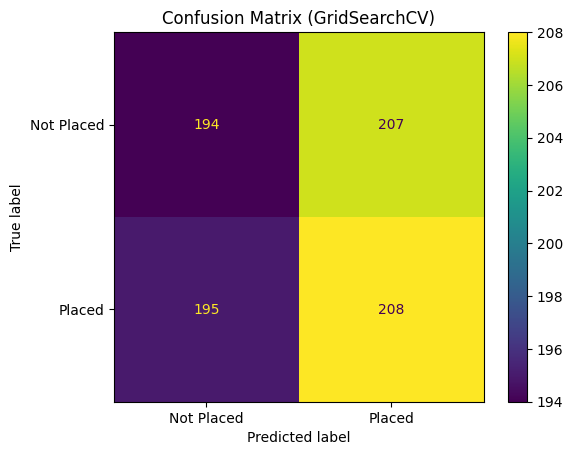

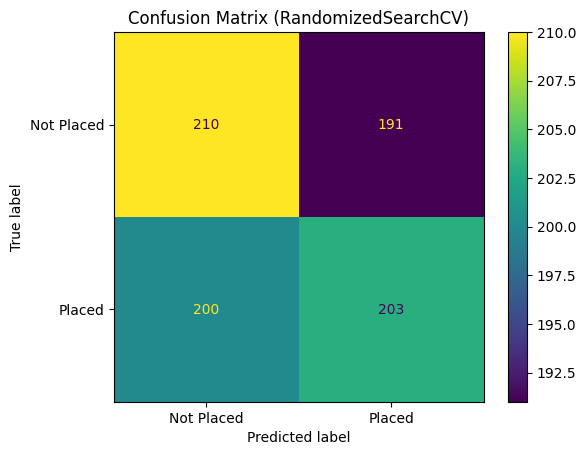

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve

# Confusion Matrix for GridSearchCV Model
cm_grid = confusion_matrix(y_test, y_pred_rf_grid)
disp_grid = ConfusionMatrixDisplay(confusion_matrix=cm_grid, display_labels=['Not Placed', 'Placed'])
disp_grid.plot()
plt.title('Confusion Matrix (GridSearchCV)')
plt.show()

# Confusion Matrix for RandomizedSearchCV Model
cm_random = confusion_matrix(y_test, y_pred_rf_random)
disp_random = ConfusionMatrixDisplay(confusion_matrix=cm_random, display_labels=['Not Placed', 'Placed'])
disp_random.plot()
plt.title('Confusion Matrix (RandomizedSearchCV)')
plt.show()
